## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt # viz

In [3]:
df=pd.read_csv(r"C:\Users\SAMSUNG\Desktop\DSML_Lab\Week2\Day4\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [10]:
num=df.select_dtypes(include="number")
num.isna().sum()

uid                  0
stars                0
reviews              0
price                0
boughtInLastMonth    0
dtype: int64

In [11]:
cat=df.select_dtypes(exclude="number")
cat.isna().sum()

asin            0
title           0
isBestSeller    0
category        0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.eq(" ").sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64


### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?


In [14]:
df.category.info()

<class 'pandas.core.series.Series'>
RangeIndex: 2443651 entries, 0 to 2443650
Series name: category
Non-Null Count    Dtype 
--------------    ----- 
2443651 non-null  object
dtypes: object(1)
memory usage: 18.6+ MB


In [ ]:
#category==>frequency table
frequencyT=df['category'].value_counts().sort_values(ascending=False).reset_index()
frequencyT.columns=['category', 'frequency']
frequencyT

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Motorbike Chassis,107
292,Alexa Built-In Devices,107
293,Plugs,107
294,Smart Home Security & Lighting,104


In [41]:
#category==>proportion table
proportionT=df.category.value_counts(normalize=True).round(5).sort_values(ascending=False).reset_index()
proportionT.columns=['category', 'proportion']
proportionT

,category,proportion
0,Sports & Outdoors,0.34222
1,Beauty,0.00790
2,"Handmade Clothing, Shoes & Accessories",0.00787
3,Bath & Body,0.00781
4,Birthday Gifts,0.00777
...,...,...
291,Motorbike Chassis,0.00004
292,Alexa Built-In Devices,0.00004
293,Plugs,0.00004
294,Smart Home Security & Lighting,0.00004


In [ ]:
#top5 category (Frequency)
top5category=frequencyT.head(5)
top5category

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978


In [44]:
top20category=frequencyT.head(20)
top20category

,category,frequency
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
5,Manicure & Pedicure Products,18940
6,Skin Care,18769
7,Make-up,18756
8,Hair Care,18735
9,Fragrances,18564


In [53]:
#top10 category (Proportion)
top20category=proportionT.head(20)
top20category

,category,proportion
0,Sports & Outdoors,0.34222
1,Beauty,0.00790
2,"Handmade Clothing, Shoes & Accessories",0.00787
3,Bath & Body,0.00781
4,Birthday Gifts,0.00777
5,Manicure & Pedicure Products,0.00775
6,Make-up,0.00768
7,Skin Care,0.00768
8,Hair Care,0.00767
9,Fragrances,0.00760



2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

C:\Users\SAMSUNG\AppData\Local\Temp\ipykernel_4752\1929995284.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


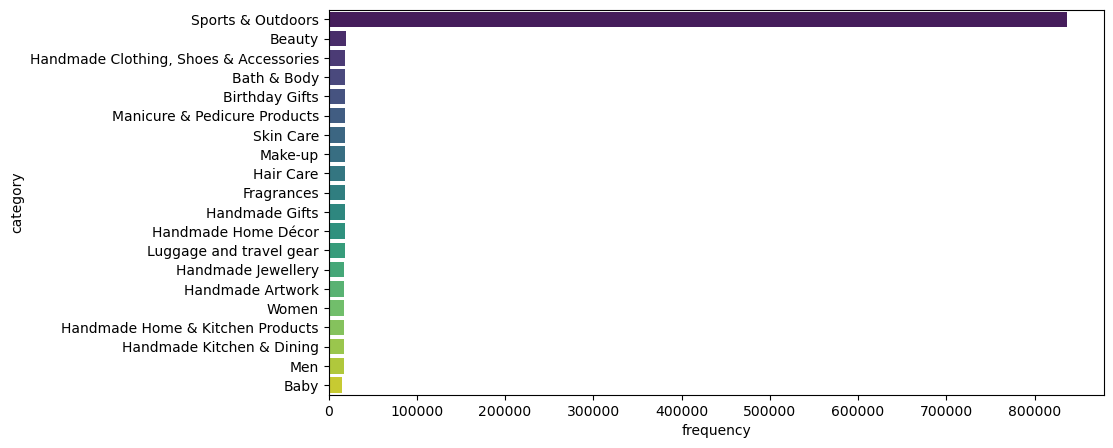

In [ ]:
#top20 category based on the frequency
plt.figure(figsize=(10, 5)) 
sns.barplot(
    y="category",
    x="frequency",
    data=top20category,
    palette='viridis',
    legend=True,
)
plt.show()

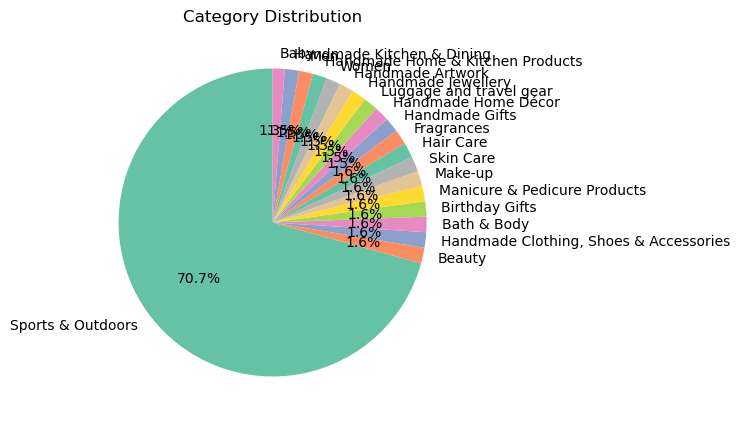

In [54]:
#top20 category based on the proportion
plt.figure(figsize=(10, 5)) 
plt.pie(
    top20category['proportion'],
    labels=top20category['category'],
    autopct='%1.1f%%',      # show percentages
    startangle=90,          # rotate start
    colors=plt.cm.Set2.colors  # nice color palette
)
plt.title('Category Distribution')
plt.show()

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?


In [61]:
df['price'].describe().round(1)


#mean=89.2

count    2443651.0
mean          89.2
std          345.6
min            0.0
25%           10.0
50%           19.1
75%           46.0
max       100000.0
Name: price, dtype: float64

In [62]:
round(float(df['price'].mean()),1)


89.2

In [63]:
df['price'].mode()


0    9.99
Name: price, dtype: float64

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [74]:
round(df['price'].var(), 1)

119445.5

In [75]:
df['price'].std()

345.60886175352226

In [76]:
df['price'].max()

100000.0

In [77]:
df['price'].min()

0.0

In [78]:
#price range
print(df['price'].min(), "to", df['price'].max())

0.0 to 100000.0


In [79]:
inter=df['price'].quantile(0.75)-df['price'].quantile(0.25)
inter

np.float64(36.0)

In [80]:
round(float(df['price'].skew()), 2)


27.49

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

In [ ]:
#It's hard to read the histogram, since the price range is extremely wide(from 0 to 100000). I can see that most product fall into a specific price range(approximately, between 0 to 5000?).

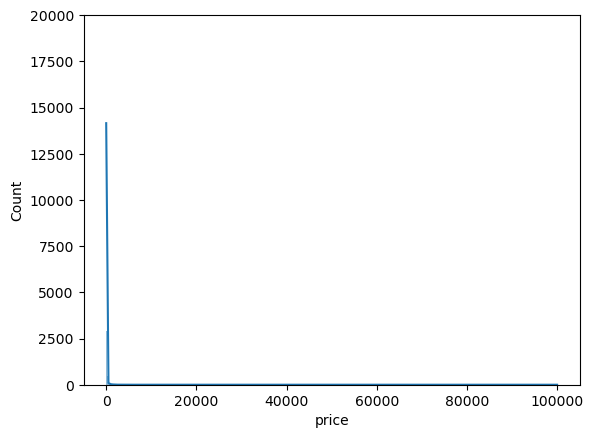

In [87]:
sns.histplot(num.price, bins="auto", kde=True)

plt.ylim(0, 20000)   # fix y-axis range
plt.show()

In [ ]:
#Using the box plot, I can clearly see some outliers which have significantly higher prices than others. 

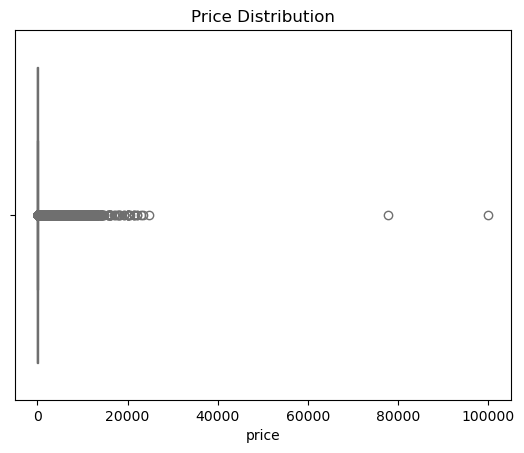

In [90]:
sns.boxplot(x=df['price'], color='skyblue')
plt.title('Price Distribution')
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [96]:
df['reviews'].describe()

count    2.443651e+06
mean     4.806278e+02
std      5.944124e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      5.900000e+01
max      1.356658e+06
Name: reviews, dtype: float64

In [ ]:
round(float(df['reviews'].mean()), 2)

480.63

In [101]:
df['reviews'].median()

0.0

In [102]:
df['reviews'].mode()

0    0
Name: reviews, dtype: int64

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?


In [103]:
df['reviews'].std()

5944.124150942261

In [ ]:
df['reviews'].var()

35332611.92181505

In [113]:
range=df['reviews'].max()-df['reviews'].min()
range


1356658

In [107]:
inter=df['reviews'].quantile(0.75)-df['reviews'].quantile(0.25)
inter

np.float64(59.0)

In [ ]:
#there is a wide variation in customer feedback

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [ ]:
round(float(df['reviews'].skew()), 2)
#Positive skew → tail on right → most data lean towards lowerer values

102.82

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [ ]:
sns.histplot(df.reviews, bins="auto", kde=True)
plt.show()